# MenuScan TN – Exploration des données

**Référence :** MS-DATA-EXP-001 · **Version :** 1.0 · **Date :** 23/11/2026 · **Auteure :** Sarra Abdeljaouad

Objectif : prendre en main le jeu de données avant l'audit qualité et le plan d'intégration.
1. Inventorier la couche brute et ses formats.
2. Mesurer les volumes de la couche de référence.
3. Explorer les grands thèmes métier : parc et revenu, résiliation, acquisition, activité en salle, menus et prix.
4. Noter les premiers constats de qualité, à approfondir dans le rapport d'audit.

*Données fictives : MenuScan TN est une entreprise simulée.*

In [1]:
import os, glob, gzip, json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Chemin du jeu de données : à adapter à ton poste
DATA = Path(os.environ.get("MENUSCAN_DATA", "../../menuscan_dataset"))
BRUT, REF = DATA / "donnees_brutes", DATA / "donnees_reference"
BLEU, MARINE, CLAIR = "#1F6FB2", "#0B3C6E", "#9DC3E6"
plt.rcParams.update({"figure.figsize": (9, 3.6), "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.max_columns", 20)
print("Jeu de données :", DATA.name, "| existe :", DATA.exists())

Jeu de données : menuscan_dataset | existe : True


## 1. Inventaire de la couche brute

In [2]:
fichiers = [p for p in BRUT.rglob("*") if p.is_file()]
inv = pd.DataFrame({"famille": [p.relative_to(BRUT).parts[0] if p.relative_to(BRUT).parts[0] != "ventes" else "/".join(p.relative_to(BRUT).parts[:2]) for p in fichiers],
                    "taille_mo": [p.stat().st_size / 1e6 for p in fichiers]})
synthese = inv.groupby("famille").agg(fichiers=("taille_mo", "size"), taille_mo=("taille_mo", "sum")).round(1)
print(len(fichiers), "fichiers,", round(inv.taille_mo.sum(), 1), "Mo")
synthese

124 fichiers, 46.2 Mo


,fichiers,taille_mo
famille,,
backoffice,4,0.4
crm,1,0.2
facturation,1,0.4
marketing,2,0.1
menus,3,1.6
paiements_api,1,0.9
referentiels,3,0.1
support,1,0.1
tracking,36,20.8


Trois formats différents cohabitent : CSV standard, CSV au format français, JSON (compressé pour le tracking).

In [3]:
print(open(BRUT / "facturation/factures.csv", encoding="utf-8").read().splitlines()[1])
with gzip.open(BRUT / "tracking/events_2025_06.jsonl.gz", "rt", encoding="utf-8") as f:
    print(json.loads(f.readline()))
print(open(BRUT / "paiements_api/paiements.jsonl", encoding="utf-8").readline().strip())

FAC000001;ETB0001;ABN00001;mise_en_place;03/01/2024;03/01/2024;03/01/2024;150,0;0,0;;150,0;28,5;178,5;18/01/2024;payee
{'event_id': 'EVT000249186', 'event_type': 'cart_add', 'ts': '2025-05-01T06:07:08Z', 'session_token': 'SES0036673', 'venue_id': 'ETB0019', 'table_ref': 'TBL00323', 'device': 'android', 'lang': 'ar', 'item_id': 'ART000520', 'qty': 1}
{"payment_id": "PAY000001", "invoice_ref": "FAC000001", "customer_ref": "ETB0001", "method": "MOBILE_WALLET", "amount": {"value": 178.5, "currency": "TND"}, "status": "SUCCEEDED", "error_code": null, "attempt": 1, "created_at": "2024-01-04T07:07:00Z"}


Constats : séparateur `;` et virgule décimale dans la facturation ; horodatages en UTC (suffixe `Z`) et libellés anglais dans le tracking et l'API ; montant imbriqué dans un objet `amount`.

## 2. Volumes de la couche de référence

In [4]:
tables = {p.stem: p for p in REF.glob("*.csv")}
vol = {t: sum(1 for _ in open(p, encoding="utf-8")) - 1 for t, p in tables.items()}
vol["evenements"] = sum(sum(1 for _ in open(p, encoding="utf-8")) - 1 for p in (REF / "evenements").glob("*.csv"))
pd.Series(vol, name="lignes").sort_values(ascending=False).to_frame()

,lignes
evenements,1601767
sessions,296166
lignes_commande,239732
commandes,106682
articles_prix_historique,14107
articles,10717
tables_salle,7151
paiements,3596
factures,3549
marketing_depenses_quotidiennes,2883


## 3. Parc et revenu récurrent

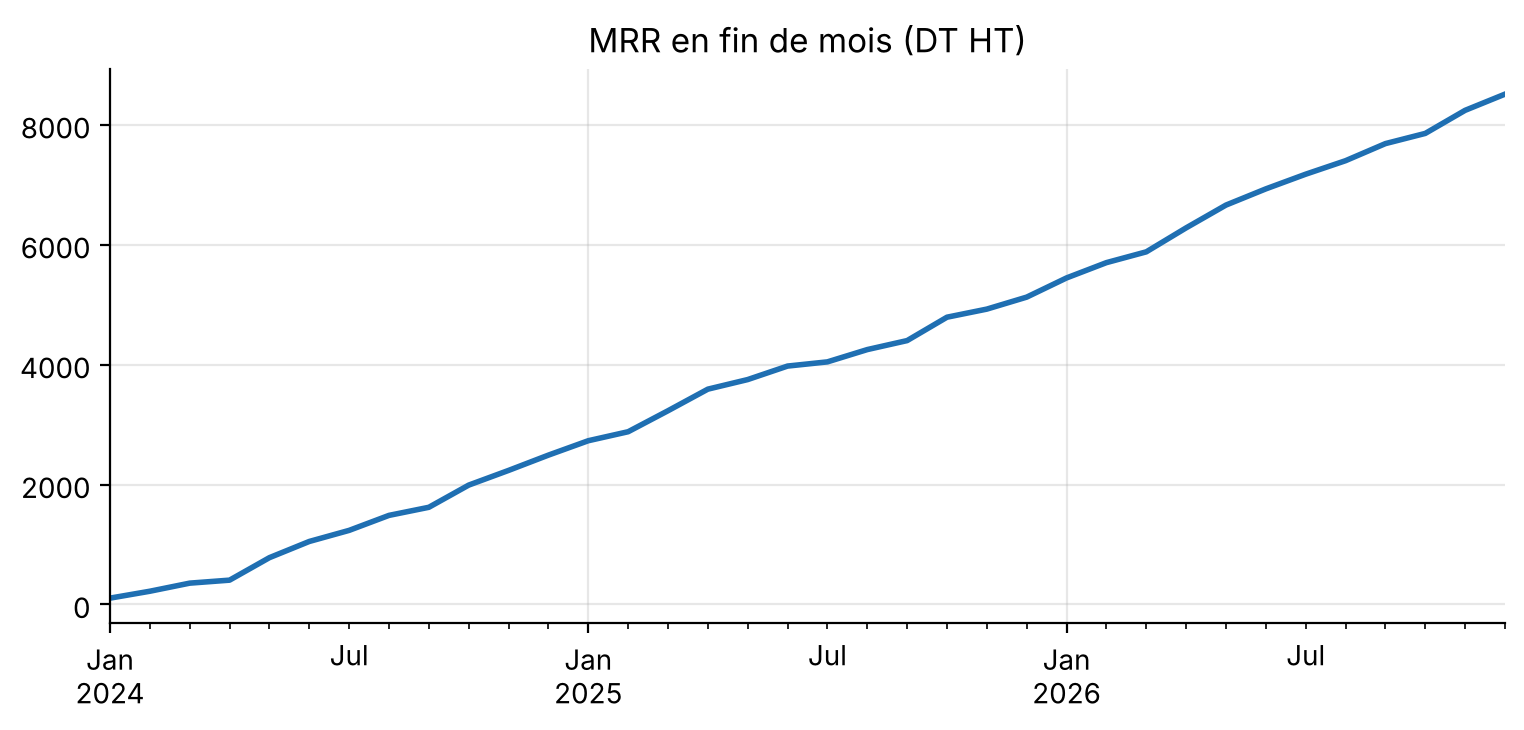

,actifs,mrr_ht
2024-12-31,77,2490.0
2025-12-31,162,5125.0
2026-12-31,265,8510.0


In [5]:
etab = pd.read_csv(REF / "etablissements.csv", parse_dates=["date_signature", "date_mise_en_service", "date_resiliation"])
abo = pd.read_csv(REF / "abonnements.csv", parse_dates=["date_debut", "date_fin"])
fins = pd.date_range("2024-01-31", "2026-12-31", freq="ME")
actif = lambda d: abo[(abo.date_debut <= d) & (abo.date_fin.isna() | (abo.date_fin >= d))]
mrr = pd.DataFrame({"actifs": [len(actif(d)) for d in fins], "mrr_ht": [actif(d).prix_mensuel_ht.sum() for d in fins]}, index=fins)
ax = mrr.mrr_ht.plot(color=BLEU, lw=2, title="MRR en fin de mois (DT HT)")
ax.set_xlabel("")
plt.show()
mrr.loc[["2024-12-31", "2025-12-31", "2026-12-31"]]

In [6]:
fin26 = actif(pd.Timestamp("2026-12-31"))
fin26.groupby("formule_id").agg(etablissements=("abonnement_id", "size"), mrr_ht=("prix_mensuel_ht", "sum"))

,etablissements,mrr_ht
formule_id,,
FRM01,107,1605.0
FRM02,103,3605.0
FRM03,55,3300.0


## 4. Résiliation

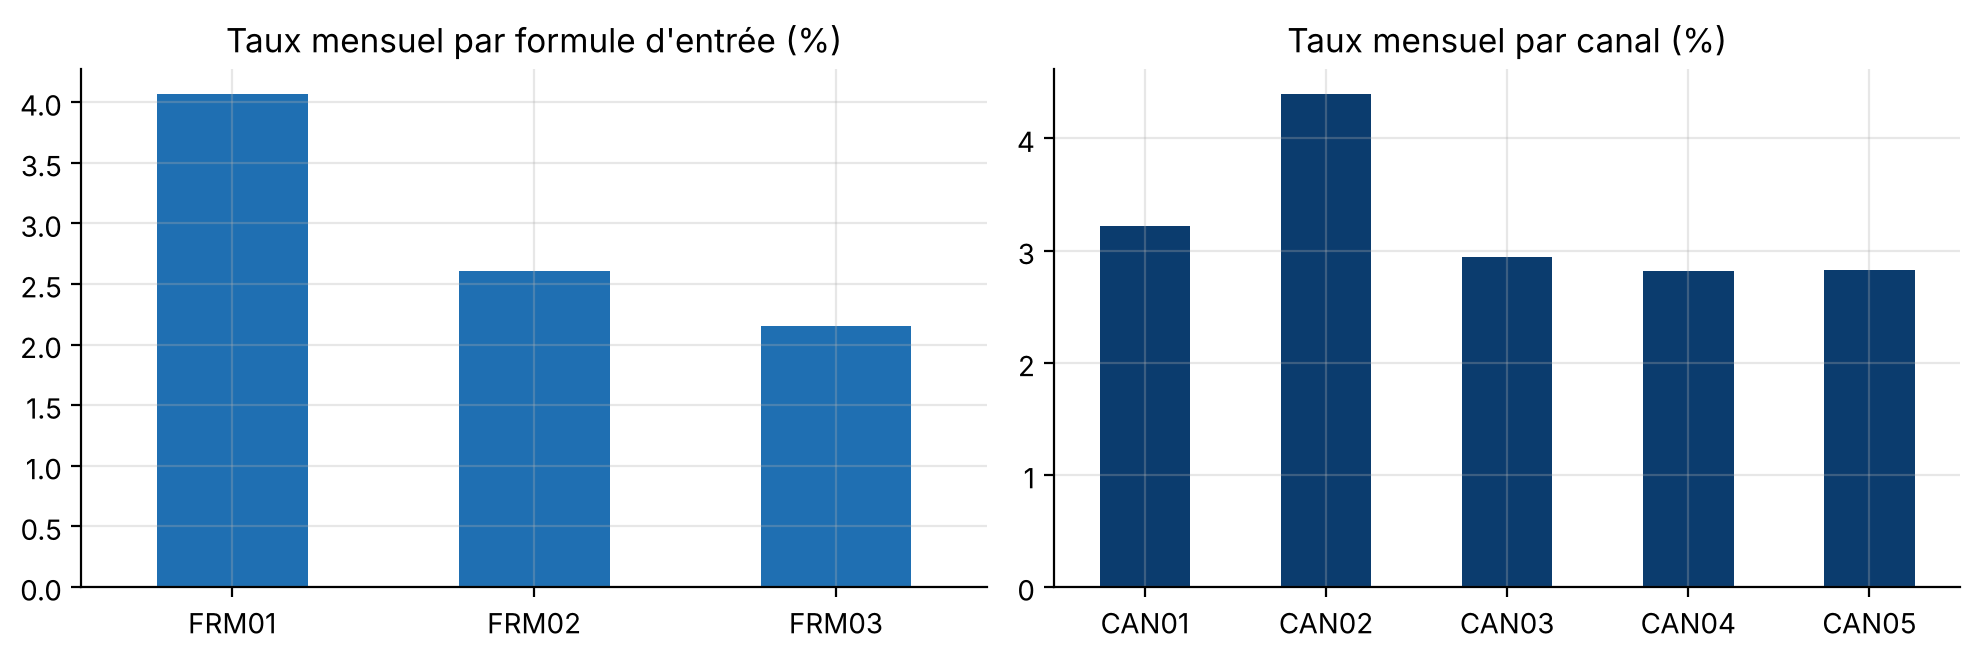

,résiliations
motif_resiliation,
peu_utilise_par_les_clients,57
prix_trop_eleve,32
sans_motif,20
fermeture_etablissement,13
changement_proprietaire,10
passage_concurrent,6


In [7]:
fin = pd.Timestamp("2026-12-31")
etab["mois_exposition"] = (etab.date_resiliation.fillna(fin) - etab.date_mise_en_service).dt.days / 30.44
def taux(col):
    g = etab.groupby(col).agg(resiliations=("date_resiliation", lambda s: s.notna().sum()), mois=("mois_exposition", "sum"))
    g["taux_mensuel_pct"] = (100 * g.resiliations / g.mois).round(2)
    return g
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
taux("formule_initiale_id").taux_mensuel_pct.plot.bar(ax=axes[0], color=BLEU, title="Taux mensuel par formule d'entrée (%)", rot=0)
taux("canal_id").taux_mensuel_pct.plot.bar(ax=axes[1], color=MARINE, title="Taux mensuel par canal (%)", rot=0)
for a in axes: a.set_xlabel("")
plt.tight_layout(); plt.show()
etab.motif_resiliation.value_counts().to_frame("résiliations")

La formule Essentiel et le canal TikTok résilient le plus. Le premier motif déclaré est l'usage faible : il faudra mesurer l'usage de chaque établissement.

## 5. Acquisition

In [8]:
pros = pd.read_csv(REF / "prospects.csv")
camp = pd.read_csv(REF / "campagnes_marketing.csv")
dep = pd.read_csv(REF / "marketing_depenses_quotidiennes.csv").merge(camp[["campagne_id", "canal_id"]])
acq = pros.groupby("canal_id").agg(prospects=("prospect_id", "size"), convertis=("statut_prospect", lambda s: (s == "converti").sum()))
acq["conversion_pct"] = (100 * acq.convertis / acq.prospects).round(1)
acq["depense_ttc"] = dep.groupby("canal_id").depense_ttc.sum().round(0)
acq["cac_ttc"] = (acq.depense_ttc / acq.convertis).round(1)
acq

,prospects,convertis,conversion_pct,depense_ttc,cac_ttc
canal_id,,,,,
CAN01,812,113,13.9,8099.0,71.7
CAN02,757,53,7.0,2345.0,44.2
CAN03,399,143,35.8,10126.0,70.8
CAN04,104,56,53.8,970.0,17.3
CAN05,174,38,21.8,4200.0,110.5


## 6. Activité en salle

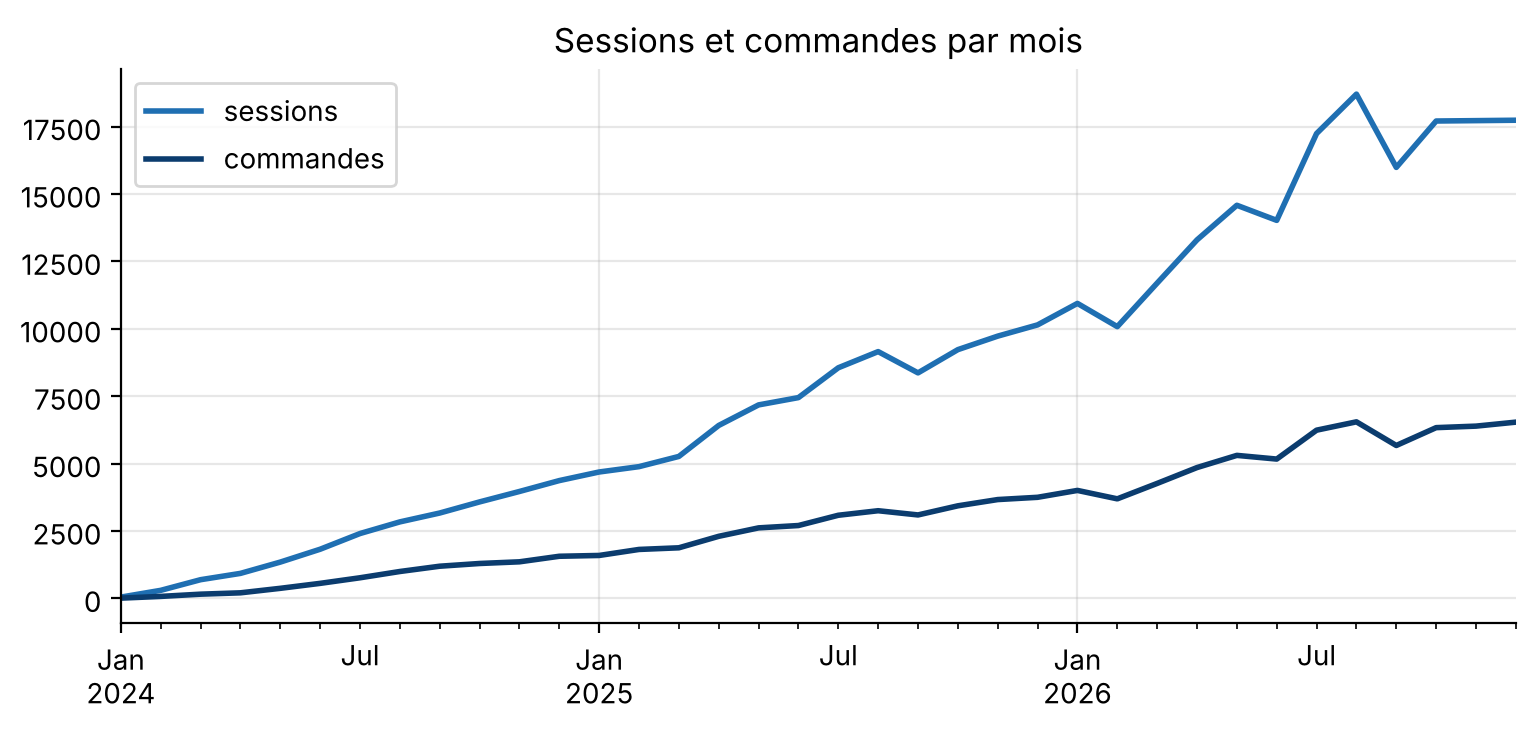

In [9]:
ses = pd.read_csv(REF / "sessions.csv", parse_dates=["debut_session"])
cmd = pd.read_csv(REF / "commandes.csv", parse_dates=["date_heure_commande"])
mois = pd.DataFrame({"sessions": ses.groupby(ses.debut_session.dt.to_period("M")).size(),
                     "commandes": cmd.groupby(cmd.date_heure_commande.dt.to_period("M")).size()})
ax = mois.plot(color=[BLEU, MARINE], lw=2, title="Sessions et commandes par mois")
ax.set_xlabel("")
plt.show()

In [10]:
f = abo.assign(fin=abo.date_fin.fillna(pd.Timestamp("2099-01-01")))
x = ses.merge(f[["etablissement_id", "formule_id", "date_debut", "fin"]], on="etablissement_id")
x = x[(x.debut_session.dt.normalize() >= x.date_debut) & (x.debut_session.dt.normalize() <= x.fin)]
entonnoir = x.groupby("formule_id").agg(sessions=("session_id", "size"), vue_article=("nb_articles_vus", lambda s: (s > 0).mean()),
                                         panier=("a_ajoute_panier", "mean"), commande=("a_commande", "mean"))
(entonnoir.assign(**{c: (100 * entonnoir[c]).round(1) for c in ["vue_article", "panier", "commande"]}))

,sessions,vue_article,panier,commande
formule_id,,,,
FRM01,124798,86.4,0.0,0.0
FRM02,112249,86.6,68.0,60.0
FRM03,59119,86.1,74.6,66.5


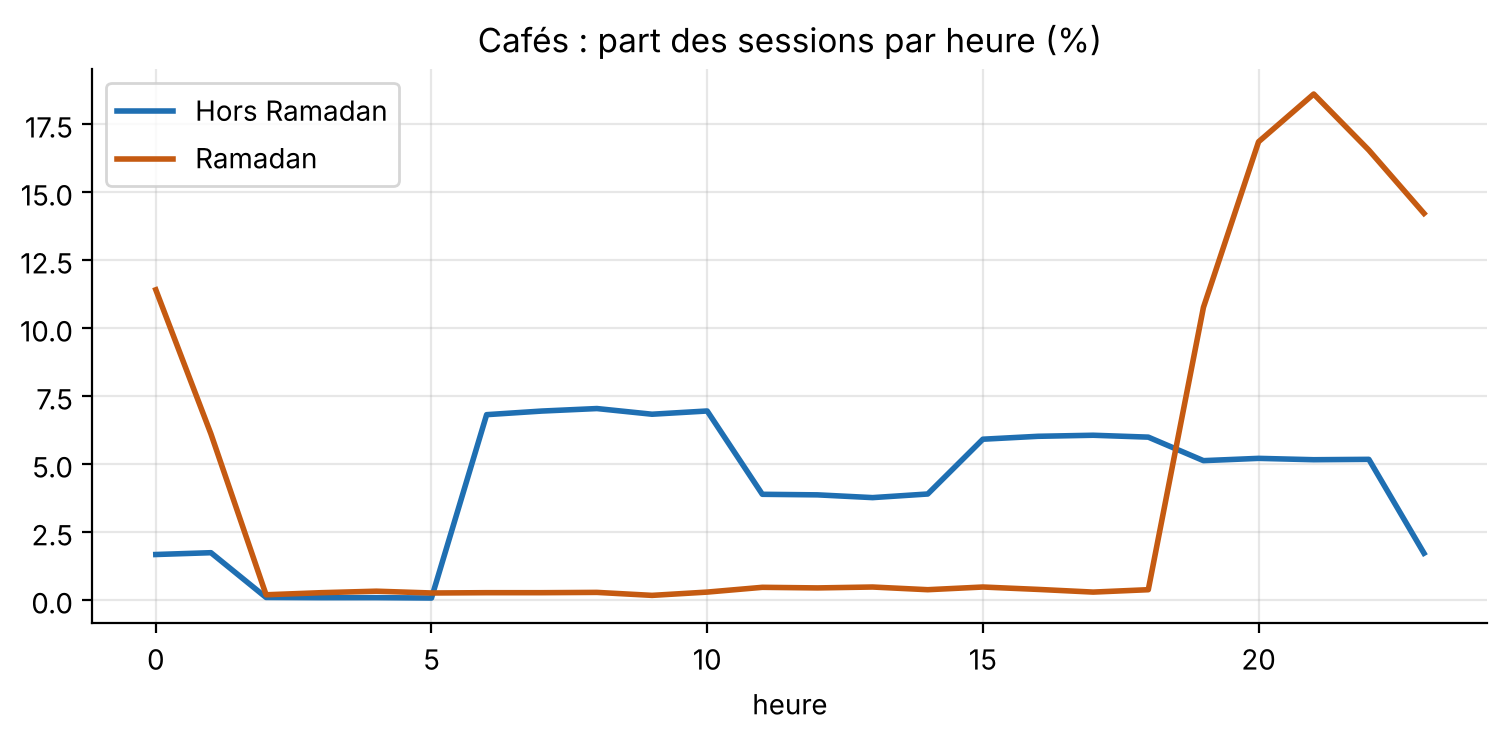

In [11]:
cal = pd.read_csv(REF / "dim_calendrier.csv", parse_dates=["date"])
cafes = ses.merge(etab[["etablissement_id", "type_etablissement"]]).query("type_etablissement == 'cafe'")
cafes = cafes.merge(cal[["date", "est_ramadan"]], left_on=cafes.debut_session.dt.normalize(), right_on="date")
h = cafes.groupby(["est_ramadan", cafes.debut_session.dt.hour]).size().unstack(0)
h = 100 * h / h.sum()
ax = h.plot(color=[BLEU, "#C55A11"], lw=2, title="Cafés : part des sessions par heure (%)")
ax.legend(["Hors Ramadan", "Ramadan"]); ax.set_xlabel("heure")
plt.show()

Pendant le Ramadan, l'activité des cafés bascule après la rupture du jeûne : de 19 h à 1 h, avec un maximum vers 21 h. La journée est presque vide.

## 7. Menus et prix

In [12]:
art = pd.read_csv(REF / "articles.csv").merge(pd.read_csv(REF / "categories_menu.csv")[["categorie_id", "nom_categorie"]])
prix = pd.read_csv(REF / "articles_prix_historique.csv")
print(len(art), "articles ;", round(art.groupby("etablissement_id").size().mean(), 1), "par établissement")
art.groupby("nom_categorie").prix_actuel_ttc.median().sort_values().round(2).to_frame("prix médian TTC").T

10717 articles ; 26.6 par établissement


nom_categorie,Viennoiseries,Boissons chaudes,Thés et infusions,Pâtisseries,Boissons fraîches,Accompagnements,Sandwichs,Entrées,Jus frais,Glaces,Desserts,Crêpes et gaufres,Chicha,Petit-déjeuner,Burgers,Tacos,Pizzas,Pâtes,Grillades,Plats
prix médian TTC,2.6,3.4,3.45,3.9,4.1,5.2,5.4,6.3,6.8,6.8,7.1,9.2,12.0,12.5,13.0,14.0,16.5,20.5,22.0,26.75


In [13]:
prix.motif_changement.value_counts().to_frame("périodes de prix")

,périodes de prix
motif_changement,
creation,10717
revision_annuelle,2679
repositionnement,540
hausse_cout_cafe,171


## 8. Premiers constats de qualité sur la couche brute

In [14]:
cb = pd.concat([pd.read_csv(p, dtype=str) for p in sorted((BRUT / "ventes/commandes").glob("*.csv"))])
print("Commandes brutes :", len(cb), "| identifiants en double :", cb.commande_id.duplicated().sum())
print("Statuts :", cb.statut_commande.value_counts().to_dict())
print("Dates non ISO :", (~cb.date_heure_commande.str.match(r"\d{4}-\d{2}-\d{2} ")).sum())
px_brut = pd.read_csv(BRUT / "menus/articles_prix_historique.csv")
print("Prix d'articles supérieurs à 200 DT :", (px_brut.prix_ttc > 200).sum(), "| maximum :", px_brut.prix_ttc.max())

Commandes brutes : 107098 | identifiants en double : 427
Statuts : {'servie': 101770, 'annulee': 3187, 'SERVIE': 705, 'Servie': 696, 'served': 676, 'Annulée': 31, 'cancelled': 17, 'ANNULEE': 16}
Dates non ISO : 1069
Prix d'articles supérieurs à 200 DT : 42 | maximum : 36500.0


## 9. Conclusions

- La couche brute mélange trois formats, deux fuseaux horaires et deux langues : l'ingestion devra normaliser avant tout calcul.
- Les doublons, les statuts non normalisés, les dates au format français et les montants en millimes sont visibles dès la première lecture. L'audit complet est dans `03_rapport_audit_qualite.xlsx`.
- La table des sessions n'existe pas en brut : elle devra être reconstituée à partir des événements.
- Le métier confirme les axes du cadrage : résiliation liée à l'usage et à la formule, coût d'acquisition très variable selon le canal, forte saisonnalité (Ramadan, été).